# Phase 2 — BiLSTM

## Goal

Train a small bidirectional LSTM (BiLSTM) from scratch. Unlike TF-IDF, it reads the
word sequence in both directions. The vocabulary is built only from training data,
and validation data controls early stopping.

In [1]:
from pathlib import Path
import os

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA = PROJECT_ROOT / "data" / "processed"
IMAGES = PROJECT_ROOT / "images"
MODELS = PROJECT_ROOT / "models"
RESULTS = PROJECT_ROOT / "results"

for folder in [IMAGES, MODELS, RESULTS]:
    folder.mkdir(parents=True, exist_ok=True)

os.environ["HF_HOME"] = str(PROJECT_ROOT / ".cache" / "huggingface")
print("Project folder:", PROJECT_ROOT)

Project folder: E:\AssDS\Project


In [2]:
import copy
import json
import random
import re
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, Dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(max(1, min(8, os.cpu_count() or 1)))

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
LABEL_NAMES = ["Negative", "Neutral", "Positive"]
print("Device:", DEVICE)

Device: cpu


## 1. Load data and make a training-only validation split

In [3]:
train_df = pd.read_csv(DATA / "train.csv")
test_df = pd.read_csv(DATA / "test.csv")

fit_df, validation_df = train_test_split(
    train_df,
    test_size=0.15,
    random_state=SEED,
    stratify=train_df["label"],
)

fit_df = fit_df.reset_index(drop=True)
validation_df = validation_df.reset_index(drop=True)

print("Fit rows:", len(fit_df))
print("Validation rows:", len(validation_df))
print("Test rows:", len(test_df))

Fit rows: 13253
Validation rows: 2339
Test rows: 3898


## 2. Tokenize text and build the vocabulary from fit data only

In [4]:
def tokenize(text):
    # Keep URL/user markers and simple Roman Urdu word tokens.
    return re.findall(r"<url>|<user>|[a-zA-Z0-9']+", str(text).lower())


word_counts = Counter()
for text in fit_df["model_text"]:
    word_counts.update(tokenize(text))

MAX_VOCABULARY = 20000
PAD_TOKEN = "<pad>"
UNKNOWN_TOKEN = "<unk>"
word_to_id = {PAD_TOKEN: 0, UNKNOWN_TOKEN: 1}

for word, _ in word_counts.most_common(MAX_VOCABULARY - 2):
    word_to_id[word] = len(word_to_id)

MAX_LENGTH = 50

print("Vocabulary size:", len(word_to_id))
print("Maximum sequence length:", MAX_LENGTH)
print("Example tokens:", tokenize(fit_df.loc[0, "model_text"])[:15])

Vocabulary size: 20000
Maximum sequence length: 50
Example tokens: ['ao', 'un', 'k', 'gunah', 'kum', 'krty', 'hain']


## 3. Convert each sentence into a fixed-length sequence

In [5]:
def encode_text(text):
    token_ids = [word_to_id.get(word, word_to_id[UNKNOWN_TOKEN]) for word in tokenize(text)]
    token_ids = token_ids[:MAX_LENGTH]
    token_ids += [word_to_id[PAD_TOKEN]] * (MAX_LENGTH - len(token_ids))
    return token_ids


class SentimentDataset(Dataset):
    def __init__(self, dataframe):
        self.texts = dataframe["model_text"].tolist()
        self.labels = dataframe["label"].astype(int).tolist()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return (
            torch.tensor(encode_text(self.texts[index]), dtype=torch.long),
            torch.tensor(self.labels[index], dtype=torch.long),
        )


BATCH_SIZE = 128
fit_loader = DataLoader(SentimentDataset(fit_df), batch_size=BATCH_SIZE, shuffle=True)
validation_loader = DataLoader(SentimentDataset(validation_df), batch_size=BATCH_SIZE)
test_loader = DataLoader(SentimentDataset(test_df), batch_size=BATCH_SIZE)

example_text, example_label = next(iter(fit_loader))
print("Batch text shape:", example_text.shape)
print("Batch label shape:", example_label.shape)

Batch text shape: torch.Size([128, 50])
Batch label shape: torch.Size([128])


## 4. Define the compact BiLSTM

In [6]:
class BiLSTMSentiment(nn.Module):
    def __init__(self, vocabulary_size, embedding_size=64, hidden_size=64, number_of_classes=3):
        super().__init__()
        self.embedding = nn.Embedding(vocabulary_size, embedding_size, padding_idx=0)
        self.lstm = nn.LSTM(
            embedding_size,
            hidden_size,
            batch_first=True,
            bidirectional=True,
        )
        self.dropout = nn.Dropout(0.35)
        self.output = nn.Linear(hidden_size * 2, number_of_classes)

    def forward(self, token_ids):
        embedded = self.embedding(token_ids)
        _, (hidden, _) = self.lstm(embedded)
        forward_last = hidden[-2]
        backward_last = hidden[-1]
        combined = torch.cat((forward_last, backward_last), dim=1)
        return self.output(self.dropout(combined))


model = BiLSTMSentiment(len(word_to_id)).to(DEVICE)
print(model)
print("Trainable parameters:", sum(parameter.numel() for parameter in model.parameters()))

BiLSTMSentiment(
  (embedding): Embedding(20000, 64, padding_idx=0)
  (lstm): LSTM(64, 64, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.35, inplace=False)
  (output): Linear(in_features=128, out_features=3, bias=True)
)
Trainable parameters: 1346947


## 5. Train with class weights and early stopping

In [7]:
class_counts = fit_df["label"].value_counts().sort_index().values
class_weights = len(fit_df) / (3 * class_counts)
loss_function = nn.CrossEntropyLoss(
    weight=torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)
)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)


def evaluate(loader):
    model.eval()
    losses = []
    predictions = []
    actual = []

    with torch.no_grad():
        for token_ids, labels in loader:
            token_ids = token_ids.to(DEVICE)
            labels = labels.to(DEVICE)
            logits = model(token_ids)
            losses.append(loss_function(logits, labels).item())
            predictions.extend(logits.argmax(dim=1).cpu().tolist())
            actual.extend(labels.cpu().tolist())

    return np.mean(losses), f1_score(actual, predictions, average="macro"), predictions, actual


history = []
best_state = None
best_validation_f1 = -1
patience = 2
epochs_without_improvement = 0
training_start = time.perf_counter()

for epoch in range(1, 6):
    model.train()
    training_losses = []

    for token_ids, labels in fit_loader:
        token_ids = token_ids.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()
        logits = model(token_ids)
        loss = loss_function(logits, labels)
        loss.backward()
        optimizer.step()
        training_losses.append(loss.item())

    validation_loss, validation_f1, _, _ = evaluate(validation_loader)
    row = {
        "epoch": epoch,
        "train_loss": float(np.mean(training_losses)),
        "validation_loss": float(validation_loss),
        "validation_macro_f1": float(validation_f1),
    }
    history.append(row)
    print(row)

    if validation_f1 > best_validation_f1:
        best_validation_f1 = validation_f1
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            print("Early stopping: validation macro-F1 stopped improving.")
            break

training_seconds = time.perf_counter() - training_start
model.load_state_dict(best_state)
print(f"Training time: {training_seconds:.1f} seconds")

{'epoch': 1, 'train_loss': 1.082142398907588, 'validation_loss': 1.046476401780781, 'validation_macro_f1': 0.4650465459333291}


{'epoch': 2, 'train_loss': 1.0077909173873754, 'validation_loss': 1.005075752735138, 'validation_macro_f1': 0.4931485965535051}


{'epoch': 3, 'train_loss': 0.9288773118303373, 'validation_loss': 0.9764287314916912, 'validation_macro_f1': 0.5284628503475778}


{'epoch': 4, 'train_loss': 0.848544798218287, 'validation_loss': 0.9510350070501629, 'validation_macro_f1': 0.549601731210235}


{'epoch': 5, 'train_loss': 0.7638021415242782, 'validation_loss': 0.9465837290412501, 'validation_macro_f1': 0.56297038853177}
Training time: 20.6 seconds


## 6. Evaluate once on the untouched test set

In [8]:
test_loss, test_macro_f1, test_predictions, test_actual = evaluate(test_loader)
test_accuracy = accuracy_score(test_actual, test_predictions)
test_weighted_f1 = f1_score(test_actual, test_predictions, average="weighted")

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test macro-F1: {test_macro_f1:.4f}")
print(
    classification_report(
        test_actual,
        test_predictions,
        labels=[0, 1, 2],
        target_names=LABEL_NAMES,
        digits=4,
        zero_division=0,
    )
)

Test loss: 0.9336
Test accuracy: 0.5800
Test macro-F1: 0.5738
              precision    recall  f1-score   support

    Negative     0.4820    0.5759    0.5248      1047
     Neutral     0.6540    0.5998    0.6257      1689
    Positive     0.5874    0.5551    0.5708      1162

    accuracy                         0.5800      3898
   macro avg     0.5745    0.5769    0.5738      3898
weighted avg     0.5879    0.5800    0.5822      3898



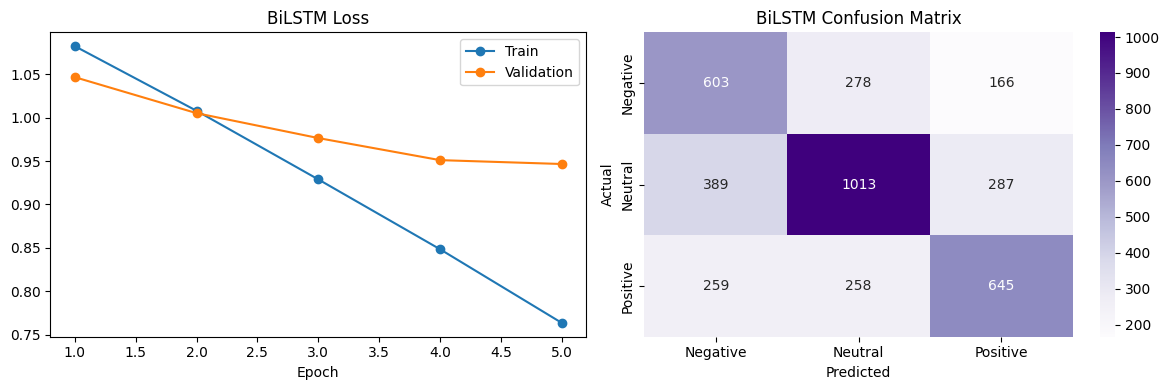

In [9]:
history_df = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train")
axes[0].plot(history_df["epoch"], history_df["validation_loss"], marker="o", label="Validation")
axes[0].set_title("BiLSTM Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()

matrix = confusion_matrix(test_actual, test_predictions, labels=[0, 1, 2])
sns.heatmap(matrix, annot=True, fmt="d", cmap="Purples", xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES, ax=axes[1])
axes[1].set_title("BiLSTM Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.savefig(IMAGES / "07_bilstm_training_and_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Save the model, vocabulary, predictions, and metrics

In [10]:
torch.save(model.state_dict(), MODELS / "bilstm_sentiment.pt")
(MODELS / "bilstm_vocabulary.json").write_text(
    json.dumps(word_to_id, ensure_ascii=False), encoding="utf-8"
)

configuration = {
    "max_length": MAX_LENGTH,
    "embedding_size": 64,
    "hidden_size": 64,
    "labels": {"0": "Negative", "1": "Neutral", "2": "Positive"},
}
(MODELS / "bilstm_config.json").write_text(json.dumps(configuration, indent=2), encoding="utf-8")

pd.DataFrame(history).to_csv(RESULTS / "bilstm_training_history.csv", index=False)
pd.DataFrame(
    [{
        "model": "BiLSTM",
        "accuracy": test_accuracy,
        "macro_f1": test_macro_f1,
        "weighted_f1": test_weighted_f1,
        "fit_seconds": training_seconds,
    }]
).to_csv(RESULTS / "bilstm_test_results.csv", index=False)

bilstm_predictions = test_df[["sentence", "sentiment", "label"]].copy()
bilstm_predictions["BiLSTM"] = test_predictions
bilstm_predictions.to_csv(RESULTS / "bilstm_test_predictions.csv", index=False)

print("Saved BiLSTM artifacts and results.")

Saved BiLSTM artifacts and results.


## Conclusion

The BiLSTM learns sequential information without pretrained language knowledge.
Early stopping keeps the best validation checkpoint and reduces overfitting.